In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [27]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 500)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [28]:
df = pd.read_csv('datasets/titanic/train.csv')

In [29]:
df.shape

(891, 12)

In [30]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


In [31]:
test = pd.read_csv('datasets/titanic/test.csv')

In [32]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.500,0,0,330911,7.829,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.000,1,0,363272,7.000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.000,0,0,240276,9.688,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.000,0,0,315154,8.662,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.000,1,1,3101298,12.287,NaN,S


In [33]:
test.shape

(418, 11)

In [34]:
genders = pd.read_csv('datasets/titanic/gender_submission.csv')

In [35]:
genders.shape

(418, 2)

In [36]:
test["Survived"] = genders["Survived"]

In [37]:
df = pd.concat([df, test], axis=0)
df = df.reset_index(drop=True)

In [38]:
df.shape

(1309, 12)

In [39]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], dtype='object')

## Case Nedir?

- Titanic gemisinin batışında yolcuların hayatta kalma durumlarını tahmin etmemiz bekleniyor (Binary Classification)

- Target değişkenimiz: Survived (0: Ölen, 1: Hayatta Kalan)

## Preprocessing Functions

In [40]:
def cat_summary(dataframe, col_name, plot=False):
    # Eğer col_name bir liste ise
    if isinstance(col_name, list):
        for col in col_name:
            print(f"\nAnalysis for {col}:")
            print(pd.DataFrame({col: dataframe[col].value_counts(),
                           "Ratio": 100 * dataframe[col].value_counts() / len(dataframe)}))
            print("##########################################")
            if plot:
                plt.figure(figsize=(8, 4))
                sns.countplot(x=dataframe[col], data=dataframe)
                plt.title(f"Distribution of {col}")
                plt.show()
    # Tek bir kolon ismi ise
    else:
        print(pd.DataFrame({col_name: dataframe[col_name].value_counts(),
                       "Ratio": 100 * dataframe[col_name].value_counts() / len(dataframe)}))
        print("##########################################")
        if plot:
            plt.figure(figsize=(8, 4))
            sns.countplot(x=dataframe[col_name], data=dataframe)
            plt.title(f"Distribution of {col_name}")
            plt.show()

In [41]:
def check_df(dataframe, head=5):
    print("##################### Shape #####################")
    print(dataframe.shape)
    print("##################### Types #####################")
    print(dataframe.dtypes)
    print("##################### Head #####################")
    print(dataframe.head(head))
    print("##################### Tail #####################")
    print(dataframe.tail(head))
    print("##################### NA #####################")
    print(dataframe.isnull().sum())
    print("##################### Quantiles #####################")
    numeric_columns = dataframe.select_dtypes(include=[np.number]).columns
    print(dataframe[numeric_columns].quantile([0, 0.05, 0.50, 0.95, 0.99, 1]).T)


In [42]:
def num_summary(dataframe, numerical_col, plot=False):
    quantiles = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
    print(dataframe[numerical_col].describe(quantiles).T)

    if plot:
        dataframe[numerical_col].hist(bins=20)
        plt.xlabel(numerical_col)
        plt.title(numerical_col)
        plt.show(block=True)

In [43]:
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit


In [44]:
def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    
    # Eğer kolon kategorik ise veya sayısal değilse False döndür
    if not np.issubdtype(dataframe[col_name].dtype, np.number):
        return False
        
    # Sayısal kolonlar için aykırı değer kontrolü
    outlier_mask = (dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)
    return outlier_mask.any()

In [45]:
def replace_with_thresholds(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    dataframe.loc[(dataframe[col_name] < low_limit), col_name] = low_limit
    dataframe.loc[(dataframe[col_name] > up_limit), col_name] = up_limit


In [46]:
def correlation_matrix(dataframe, cols):
    fig = plt.gcf()
    fig.set_size_inches(10,8)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    fig = sns.heatmap(dataframe[cols].corr(), annot=True, linewidths=0.5, annot_kws={'size': 12}, linecolor='w', cmap='RdBu')
    plt.show(block=True)

In [47]:
def grab_col_names(dataframe, cat_th=10, car_th=20):
    cat_cols = [col for col in dataframe.columns if dataframe[col].dtypes == "O"]
    #numeric olup kategorik olan değişkenler
    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and dataframe[col].dtypes != "O"]
    #kategorik olup kardinalitesi yüksek olan değişkenler
    cat_but_car = [col for col in dataframe.columns if dataframe[col].dtypes == "O" and dataframe[col].nunique() > car_th]
    cat_cols += num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]
    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != "O" and col not in num_but_cat]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f"cat_cols: {len(cat_cols)}")
    print(f"num_cols: {len(num_cols)}")
    print(f"cat_but_car: {len(cat_but_car)}")
    print(f"num_but_cat: {len(num_but_cat)}")
    
    return cat_cols, num_cols, cat_but_car


In [48]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], dtype='object')

## Feature Engineering

# Visualization

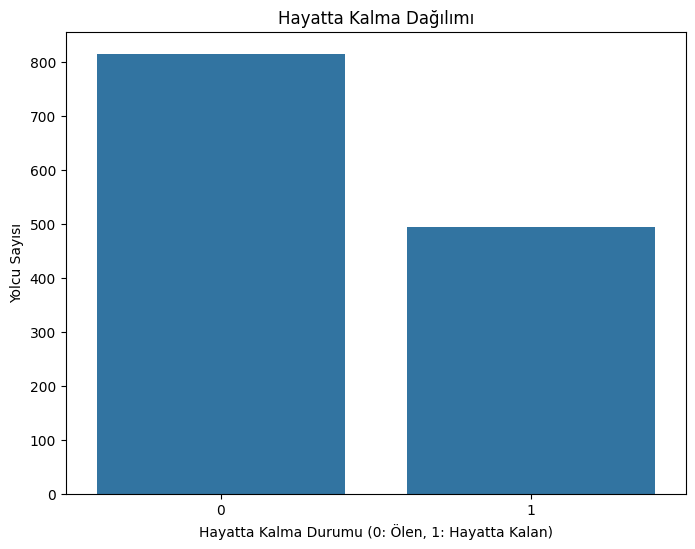

In [49]:
# Hayatta kalma oranı dağılımı
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Survived')
plt.title('Hayatta Kalma Dağılımı')
plt.xlabel('Hayatta Kalma Durumu (0: Ölen, 1: Hayatta Kalan)')
plt.ylabel('Yolcu Sayısı')
plt.show()

# Yorum: Bu grafik bize genel hayatta kalma oranını gösterir. 
# Titanik'te hayatta kalanların sayısı hayatını kaybedenlere göre daha azdır.

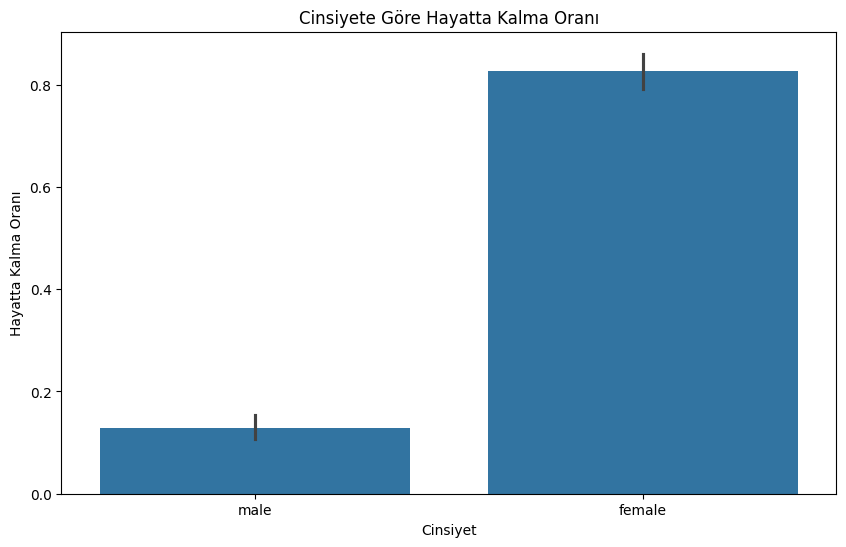

In [50]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Sex', y='Survived')
plt.title('Cinsiyete Göre Hayatta Kalma Oranı')
plt.xlabel('Cinsiyet')
plt.ylabel('Hayatta Kalma Oranı')
plt.show()

# Yorum: Kadınların hayatta kalma oranı erkeklere göre belirgin şekilde daha yüksektir.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_27304\2800333873.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  survival_rates = df.groupby(


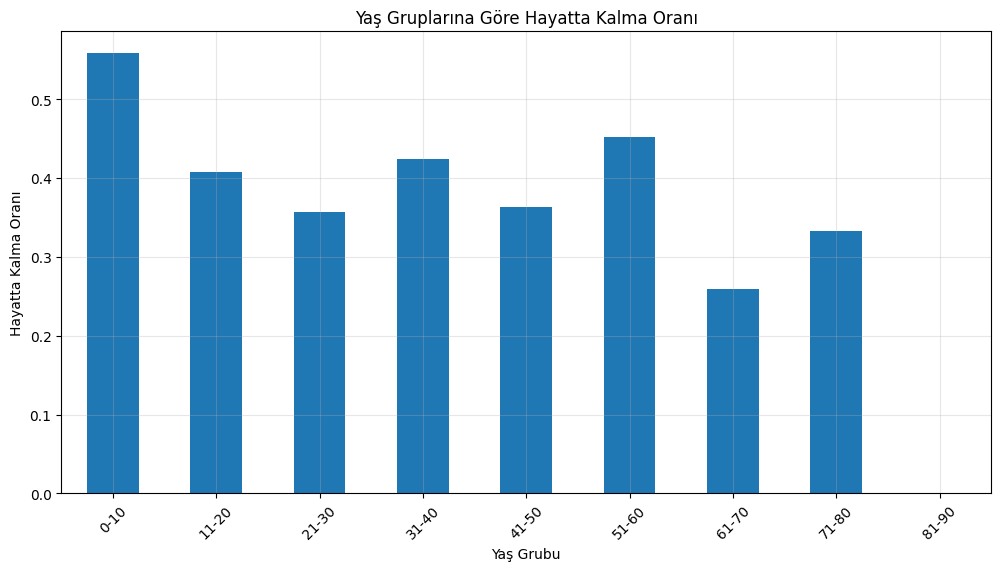

In [51]:
# Geçici yaş grupları oluştur ve hayatta kalma oranlarını hesapla
survival_rates = df.groupby(
    pd.cut(df['Age'], bins=[0, 10, 20, 30, 40, 50, 60, 70, 80, 90], 
           labels=['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90'])
)['Survived'].mean()

# Görselleştirme
plt.figure(figsize=(12, 6))
survival_rates.plot(kind='bar')
plt.title('Yaş Gruplarına Göre Hayatta Kalma Oranı')
plt.xlabel('Yaş Grubu')
plt.ylabel('Hayatta Kalma Oranı')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.show()


## Yaş ilerledikçe hayatta kalma oranlarında genel bir düşüş trendi gözlemleniyor
## Ancak bu düşüş doğrusal değil, bazı yaş gruplarında yükselmeler görülüyor
## Özellikle çocukların ve gençlerin hayatta kalma şansının daha yüksek olduğu gözlemleniyor


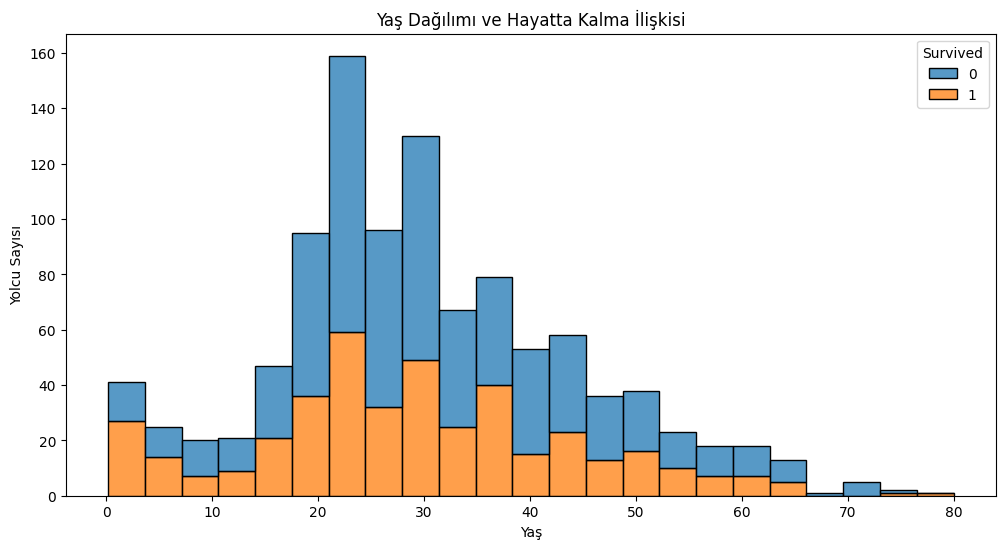

In [52]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='Age', hue='Survived', multiple="stack")
plt.title('Yaş Dağılımı ve Hayatta Kalma İlişkisi')
plt.xlabel('Yaş')
plt.ylabel('Yolcu Sayısı')
plt.show()


## Yolcuların çoğunluğı 20-40 yaş aralığında yoğunlaşmış
## En yüksek yolcu sayısı 25-30 yaş aralığında


## 0-5 yaş arası hayatta kalma oranı yüksek
## 20-40 yaş arası hayatta kalma oranı düşük
## Yaş ilerledikçe hem yolcu sayısı hem de hayatta kalma oranı düşüyor


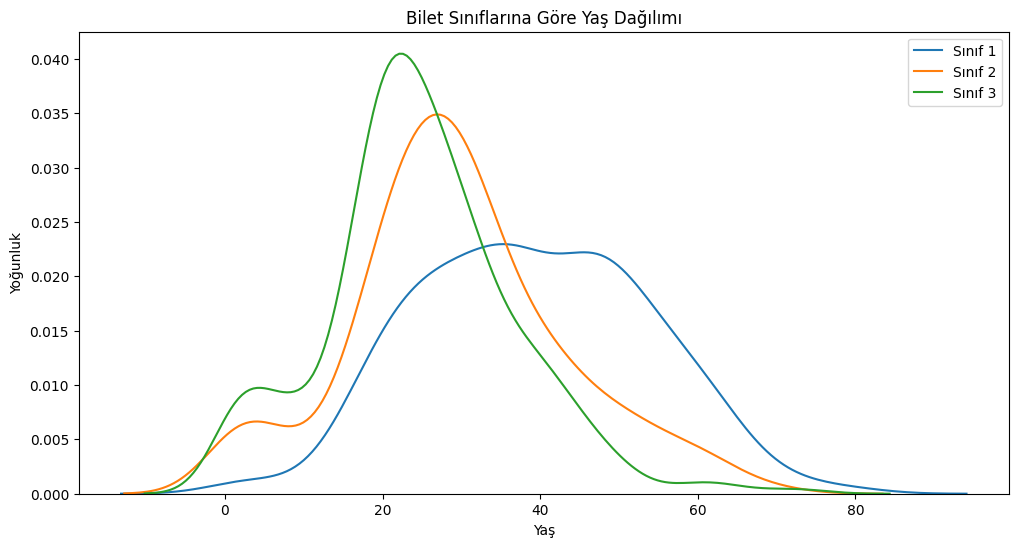

In [53]:
plt.figure(figsize=(12, 6))
for pclass in [1, 2, 3]:
    sns.kdeplot(data=df[df['Pclass'] == pclass]['Age'], 
                label=f'Sınıf {pclass}')
plt.title('Bilet Sınıflarına Göre Yaş Dağılımı')
plt.xlabel('Yaş')
plt.ylabel('Yoğunluk')
plt.legend()
plt.show()

## Üst sınıf biletler daha yaşlı ve muhtemelen daha  varlıklı yolcular
## Alt sınıf biletler daha genç

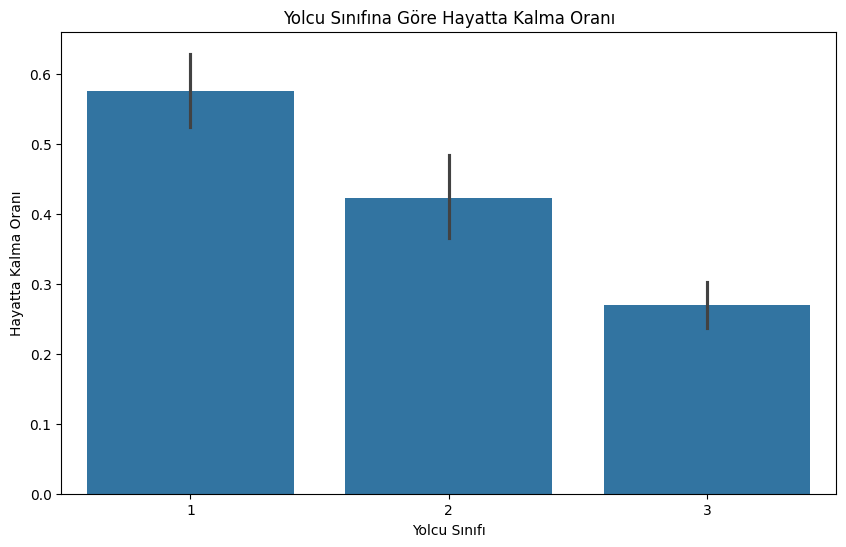

In [54]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Pclass', y='Survived')
plt.title('Yolcu Sınıfına Göre Hayatta Kalma Oranı')
plt.xlabel('Yolcu Sınıfı')
plt.ylabel('Hayatta Kalma Oranı')
plt.show()

# Yorum: 1. sınıf yolcuların hayatta kalma oranı diğer sınıflara göre daha yüksektir.
# Bu durum, üst sınıf yolcuların kurtarma botlarına erişiminin daha kolay olduğunu gösterebilir.

In [55]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], dtype='object')

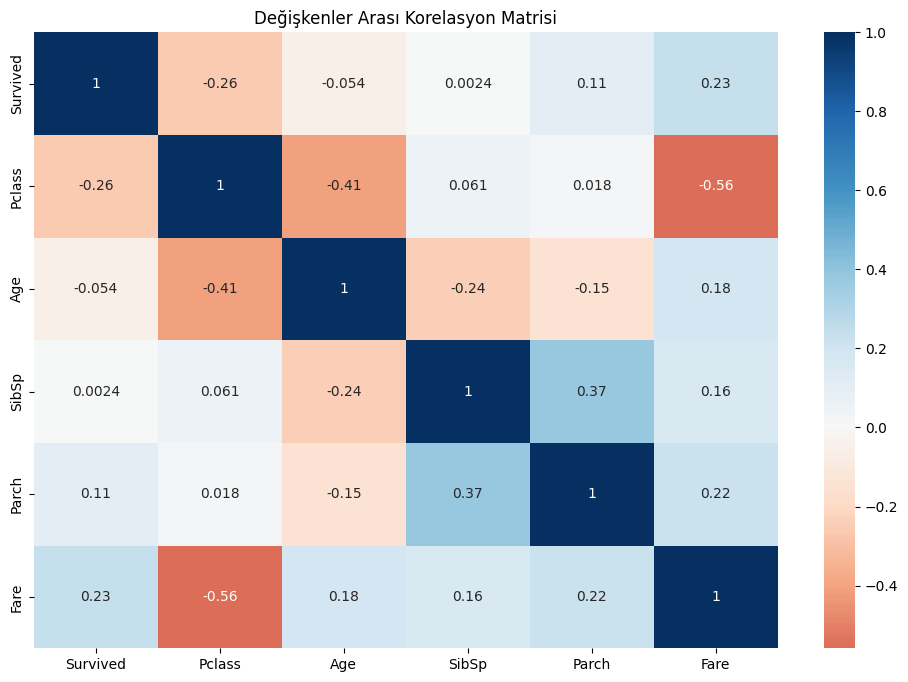

In [56]:
# Sayısal değişkenler arasındaki korelasyonu görselleştirme
plt.figure(figsize=(12, 8))
sns.heatmap(df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].corr(), 
            annot=True, 
            cmap='RdBu', 
            center=0)
plt.title('Değişkenler Arası Korelasyon Matrisi')
plt.show()

# Yorum:
# - FARE ve PCLASS arasında negatif korelasyon var (üst sınıf yolcular daha yüksek ücret ödüyor)
# - SIBSP (kardeş ve eş sayısı) ve PARCH (ebeveyn ve çocuk sayısı) arasında pozitif korelasyon var (aile üyeleri genelde birlikte seyahat ediyor)
# - SURVIVED ile PCLASS arasında negatif korelasyon var (üst sınıf yolcuların hayatta kalma oranı daha yüksek)
# - SURVIVED ile FARE arasında pozitif korelasyon var (daha yüksek ücret ödeyen yolcuların hayatta kalma oranı daha yüksek)
# - AGE ile PCLASS arasında negatif korelasyon (-0.41) var. Bu, üst sınıf yolcuların yaş ortalamasının daha yüksek olduğunu gösteriyor.
# - SURVIVED ile AGE arasındaki korelasyon çok zayıf (-0.054). Yaşın tek başına hayatta kalma üzerinde önemli bir etkisi yok.
# - SURVIVED ile PARCH (0.11) ve SIBSP (0.0024) arasındaki korelasyonlar oldukça zayıf. Aile büyüklüğünün hayatta kalma üzerinde çok belirgin bir etkisi görünmüyor.

Cinsiyet ve Yolcu Sınıfına Göre Hayatta Kalma Oranları:
Pclass     1     2     3
Sex                     
female 0.979 0.943 0.667
male   0.251 0.099 0.095


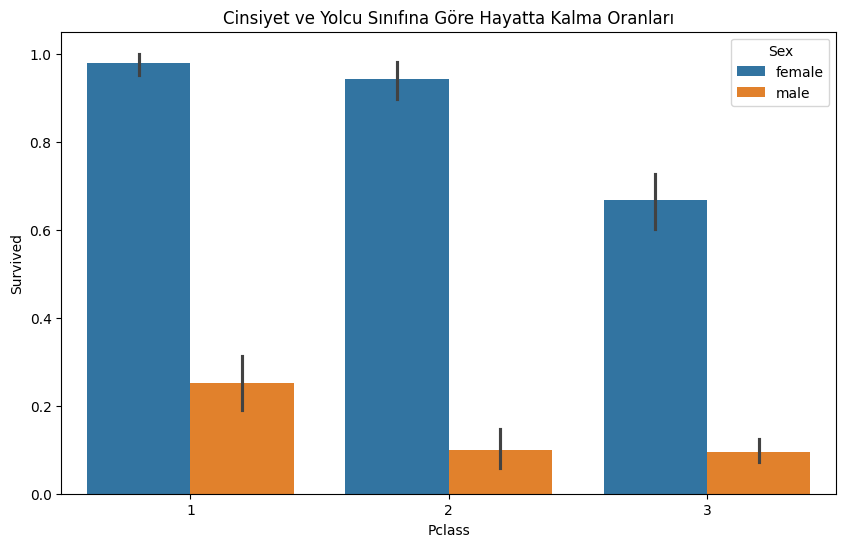

In [57]:
# Cinsiyet ve yolcu sınıfına göre hayatta kalma oranları
print("Cinsiyet ve Yolcu Sınıfına Göre Hayatta Kalma Oranları:")
print(df.groupby(['Sex', 'Pclass'])['Survived'].mean().unstack())

# Görselleştirme
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex')
plt.title('Cinsiyet ve Yolcu Sınıfına Göre Hayatta Kalma Oranları')
plt.show()

# Yorum: Hangi sınıftaki hangi cinsiyetin hayatta kalma şansı daha yüksek görebiliriz


Biniş Limanı ve Yolcu Sınıfına Göre Hayatta Kalma Oranları:
Pclass       1     2     3
Embarked                  
C        0.617 0.464 0.327
Q        0.667 0.286 0.442
S        0.537 0.421 0.218


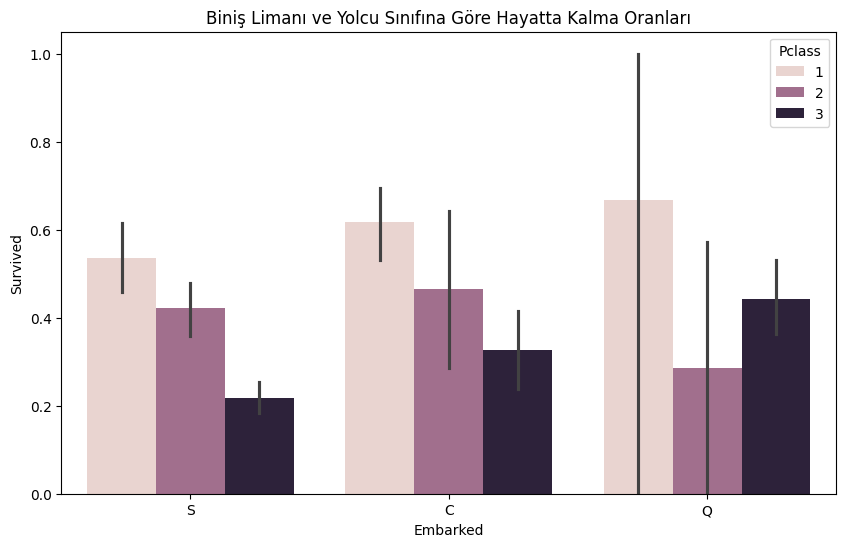

In [58]:
# Biniş limanı ve yolcu sınıfına göre hayatta kalma oranları
print("\nBiniş Limanı ve Yolcu Sınıfına Göre Hayatta Kalma Oranları:")
print(df.groupby(['Embarked', 'Pclass'])['Survived'].mean().unstack())

# Görselleştirme
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Embarked', y='Survived', hue='Pclass')
plt.title('Biniş Limanı ve Yolcu Sınıfına Göre Hayatta Kalma Oranları')
plt.show()


## 1. sınıf yolcuların hayatta kalma oranı genel olarak daha yüksek
## S de binen yolcular genel olarak en düşük hayatta kalma oranına sahip
## C de binen yolcuların hayatta kalma oranı daha dengeli bir dağılıma sahip
## Q da binen yolcularda sınıflar arası büyük farklılıklar gözlemleniyor

# Feature Extraction

In [59]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


In [60]:
# Tüm kolonları büyük harf yapıyoruz
df.columns = [col.upper() for col in df.columns]

In [61]:
df.columns

Index(['PASSENGERID', 'SURVIVED', 'PCLASS', 'NAME', 'SEX', 'AGE', 'SIBSP', 'PARCH', 'TICKET', 'FARE', 'CABIN', 'EMBARKED'], dtype='object')

In [62]:
# Cabin Bool
# Yolcuları kabin numarasına göre kategorize ediyoruz
df["NEW_CABIN_BOOL"] = df["CABIN"].notnull().astype("int")

In [63]:
df.NEW_CABIN_BOOL.head()

0    0
1    1
2    0
3    1
4    0
Name: NEW_CABIN_BOOL, dtype: int32

In [64]:
df.NEW_CABIN_BOOL.value_counts()

NEW_CABIN_BOOL
0    1014
1     295
Name: count, dtype: int64


Kabin Bilgisine Göre Hayatta Kalma Oranları:
NEW_CABIN_BOOL
0   0.310
1   0.610
Name: SURVIVED, dtype: float64


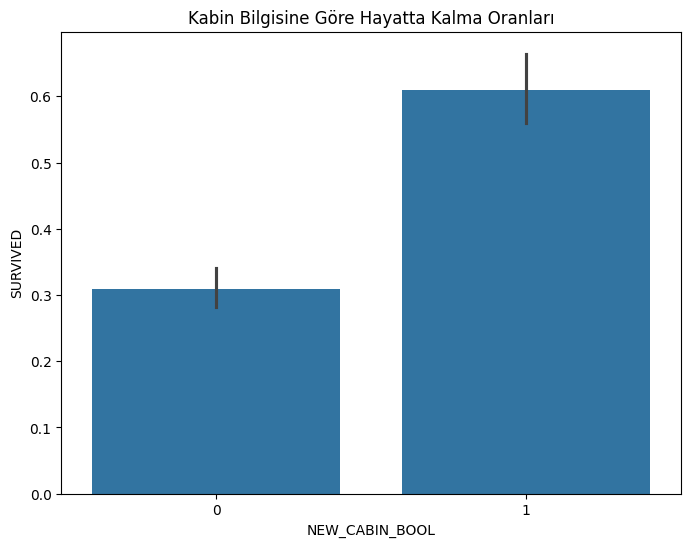

In [65]:
# Kabin bilgisi olan/olmayan yolculara göre hayatta kalma oranları
print("\nKabin Bilgisine Göre Hayatta Kalma Oranları:")
print(df.groupby('NEW_CABIN_BOOL')['SURVIVED'].mean())

# Görselleştirme
plt.figure(figsize=(8, 6))
sns.barplot(data=df, x='NEW_CABIN_BOOL', y='SURVIVED')
plt.title('Kabin Bilgisine Göre Hayatta Kalma Oranları')
plt.show()

In [66]:
# Name Count
# Yolcuların isim uzunluklarını alıyoruz
df["NEW_NAME_COUNT"] = df["NAME"].str.len()

In [67]:
df.NEW_NAME_COUNT.head()

0    23
1    51
2    22
3    44
4    24
Name: NEW_NAME_COUNT, dtype: int64

In [68]:
# New Word Count
# Yolcuların isimlerini kelime sayısına göre kategorize ediyoruz
df["NEW_NAME_WORD_COUNT"] = df["NAME"].apply(lambda x : len(str(x).split(" ")))

In [69]:
df.NEW_NAME_WORD_COUNT.head()

0    4
1    7
2    3
3    7
4    4
Name: NEW_NAME_WORD_COUNT, dtype: int64

In [70]:
# name dr
# Yolcuları doktor olup olmadıklarına göre kategorize ediyoruz
df["NEW_NAME_DR"] = df["NAME"].apply(lambda x: len([x for x in x.split() if x.startswith("Dr")]))

In [71]:
df.NEW_NAME_DR.head()

0    0
1    0
2    0
3    0
4    0
Name: NEW_NAME_DR, dtype: int64

In [72]:
df.NEW_NAME_DR.value_counts()

NEW_NAME_DR
0    1293
1      16
Name: count, dtype: int64

In [73]:
# new title
df["NEW_TITLE"] = df["NAME"].str.extract(" ([A-Za-z]+)\.", expand=False)


In [74]:
df.NEW_TITLE.head()


0      Mr
1     Mrs
2    Miss
3     Mrs
4      Mr
Name: NEW_TITLE, dtype: object

In [75]:
df.NEW_TITLE.value_counts()

NEW_TITLE
Mr          757
Miss        260
Mrs         197
Master       61
Rev           8
Dr            8
Col           4
Mlle          2
Major         2
Ms            2
Lady          1
Sir           1
Mme           1
Don           1
Capt          1
Countess      1
Jonkheer      1
Dona          1
Name: count, dtype: int64


Unvana Göre Hayatta Kalma Oranları:
           mean  count
NEW_TITLE             
Sir       1.000      1
Countess  1.000      1
Ms        1.000      2
Dona      1.000      1
Mme       1.000      1
Lady      1.000      1
Mlle      1.000      2
Mrs       0.868    197
Miss      0.788    260
Major     0.500      2
Master    0.377     61
Dr        0.375      8
Col       0.250      4
Mr        0.107    757
Jonkheer  0.000      1
Don       0.000      1
Rev       0.000      8
Capt      0.000      1


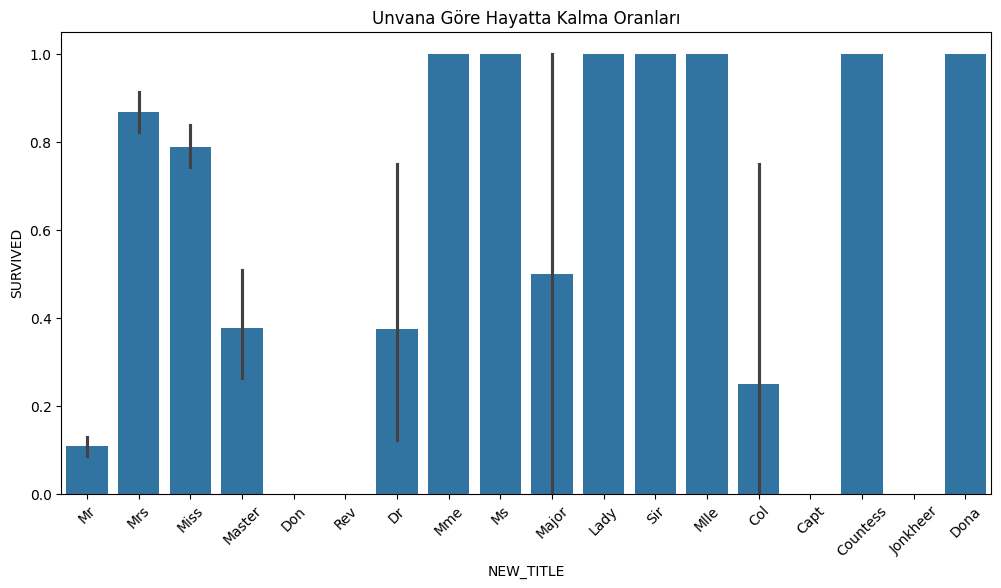

In [76]:
# Unvana göre hayatta kalma oranları
print("\nUnvana Göre Hayatta Kalma Oranları:")
print(df.groupby('NEW_TITLE')['SURVIVED'].agg(['mean', 'count']).sort_values(by='mean', ascending=False))

# Görselleştirme
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='NEW_TITLE', y='SURVIVED')
plt.title('Unvana Göre Hayatta Kalma Oranları')
plt.xticks(rotation=45)
plt.show()

In [77]:
# Family Size
# Yolcuların aile büyüklüğünü alıyoruz
df["NEW_FAMILY_SIZE"] = df["SIBSP"] + df["PARCH"] + 1
df.NEW_FAMILY_SIZE.head()

0    2
1    2
2    1
3    2
4    1
Name: NEW_FAMILY_SIZE, dtype: int64

In [78]:
df.NEW_FAMILY_SIZE.value_counts()

NEW_FAMILY_SIZE
1     790
2     235
3     159
4      43
6      25
5      22
7      16
11     11
8       8
Name: count, dtype: int64


Aile Büyüklüğüne Göre Hayatta Kalma Oranları:
                 mean  count
NEW_FAMILY_SIZE             
1               0.292    790
2               0.532    235
3               0.560    159
4               0.721     43
5               0.227     22
6               0.200     25
7               0.312     16
8               0.125      8
11              0.182     11


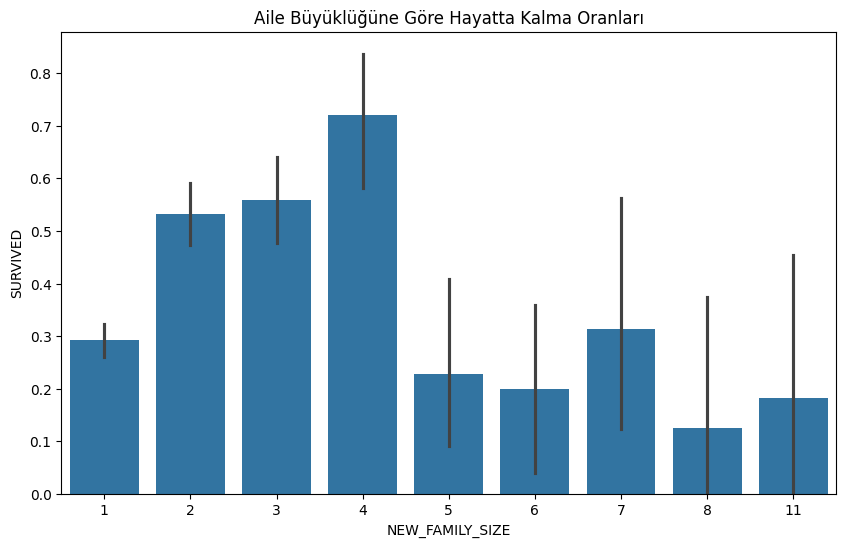

In [79]:
# Aile büyüklüğüne göre hayatta kalma oranları
print("\nAile Büyüklüğüne Göre Hayatta Kalma Oranları:")
print(df.groupby('NEW_FAMILY_SIZE')['SURVIVED'].agg(['mean', 'count']))

# Görselleştirme
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='NEW_FAMILY_SIZE', y='SURVIVED')
plt.title('Aile Büyüklüğüne Göre Hayatta Kalma Oranları')
plt.show()

In [80]:
# age_pclass
# Yolcuların yaşını ve sınıfını çarpıyoruz
df["NEW_AGE_PCLASS"] = df["AGE"] * df["PCLASS"]
df.NEW_AGE_PCLASS.head()

0    66.000
1    38.000
2    78.000
3    35.000
4   105.000
Name: NEW_AGE_PCLASS, dtype: float64

In [81]:
df.NEW_AGE_PCLASS.value_counts()

NEW_AGE_PCLASS
60.000     39
48.000     39
54.000     38
66.000     33
72.000     31
63.000     30
78.000     23
84.000     23
36.000     22
42.000     20
75.000     19
96.000     19
57.000     18
50.000     18
27.000     17
90.000     17
51.000     17
58.000     17
30.000     16
81.000     15
87.000     15
56.000     15
45.000     15
46.000     14
108.000    14
38.000     14
24.000     13
6.000      12
39.000     12
99.000     11
35.000     11
52.000     11
64.000     11
68.000     11
69.000     11
62.000     10
33.000     10
18.000     10
93.000      9
120.000     9
44.000      9
114.000     9
40.000      9
47.000      8
12.000      8
105.000     8
117.000     8
21.000      8
3.000       7
80.000      7
16.000      7
22.000      7
135.000     7
55.000      7
31.000      7
49.000      7
28.000      7
37.000      6
23.000      6
19.000      5
126.000     5
100.000     5
15.000      5
70.000      5
25.000      5
132.000     5
102.000     5
123.000     5
9.000       4
26.000      4
65.00

In [82]:
# is alone
# Yolcuların gemide yalnız mı yoksa aileyle beraber mi olduklarına göre kategorize ediyoruz
df.loc[((df["SIBSP"] + df["PARCH"]) > 0), "NEW_IS_ALONE"] = "NO"
df.loc[((df["SIBSP"] + df["PARCH"]) == 0), "NEW_IS_ALONE"] = "YES"
df.NEW_IS_ALONE.value_counts()

NEW_IS_ALONE
YES    790
NO     519
Name: count, dtype: int64

In [83]:
df.NEW_IS_ALONE.head()

0     NO
1     NO
2    YES
3     NO
4    YES
Name: NEW_IS_ALONE, dtype: object

In [84]:
df.NEW_IS_ALONE.value_counts()

NEW_IS_ALONE
YES    790
NO     519
Name: count, dtype: int64

In [85]:
# age level
# Yolcuların yaşına göre kategorize ediyoruz
df.loc[(df["AGE"] < 18), "NEW_AGE_CAT"] = "young"
df.loc[(df["AGE"] >= 18) & (df["AGE"] < 56), "NEW_AGE_CAT"] = "mature"
df.loc[(df["AGE"] >= 56), "NEW_AGE_CAT"] = "senior"
df.NEW_AGE_CAT.head()

0    mature
1    mature
2    mature
3    mature
4    mature
Name: NEW_AGE_CAT, dtype: object

In [86]:
df.NEW_AGE_CAT.value_counts()

NEW_AGE_CAT
mature    834
young     154
senior     58
Name: count, dtype: int64

In [87]:
# Sex x age
# Yolcuların cinsiyetine ve yaşına göre kategorize ediyoruz
df.loc[(df["SEX"] == "male") & (df["AGE"] <= 21), "NEW_SEX_CAT"] = "youngmale"
df.loc[(df["SEX"] == "male") & ((df["AGE"] > 21) & (df["AGE"]) <= 50), "NEW_SEX_CAT"] = "maturemale"
df.loc[(df["SEX"] == "male") & (df["AGE"] > 50), "NEW_SEX_CAT"] = "seniormale"
df.loc[(df["SEX"] == "female") & (df["AGE"] <= 21), "NEW_SEX_CAT"] = "youngfemale"
df.loc[(df["SEX"] == "female") & ((df["AGE"] > 21) & df["AGE"] <= 50), "NEW_SEX_CAT"] = "maturefemale"
df.loc[(df["SEX"] == "female") & (df["AGE"] > 50), "NEW_SEX_CAT"] = "seniorfemale"

In [88]:
df.NEW_SEX_CAT.head()

0      maturemale
1    maturefemale
2    maturefemale
3    maturefemale
4      maturemale
Name: NEW_SEX_CAT, dtype: object

In [89]:
df.NEW_SEX_CAT.value_counts()

NEW_SEX_CAT
maturemale      780
maturefemale    434
seniormale       63
seniorfemale     32
Name: count, dtype: int64

In [90]:
cat_cols, num_cols, cat_but_car = grab_col_names(df)


Observations: 1309
Variables: 22
cat_cols: 14
num_cols: 5
cat_but_car: 3
num_but_cat: 8


In [91]:
num_cols = [col for col in num_cols if col not in ["PASSENGERID"]]
num_cols

['AGE', 'FARE', 'NEW_NAME_COUNT', 'NEW_AGE_PCLASS']

                  count   mean    std    min     5%    10%    20%    30%    40%    50%    60%    70%    80%     90%     95%     max
AGE            1046.000 29.881 14.413  0.170  5.000 14.000 19.000 22.000 25.000 28.000 31.000 36.000 42.000  50.000  57.000  80.000
FARE           1308.000 33.295 51.759  0.000  7.225  7.568  7.854  8.050 10.500 14.454 21.679 26.955 41.579  78.051 133.650 512.329
NEW_NAME_COUNT 1309.000 27.131  9.507 12.000 16.000 17.000 19.000 21.000 23.200 25.000 27.000 29.000 32.000  41.200  47.000  82.000
NEW_AGE_PCLASS 1046.000 61.016 32.796  0.510 12.000 23.000 35.000 44.000 51.000 57.000 63.000 72.000 84.000 105.000 121.500 222.000


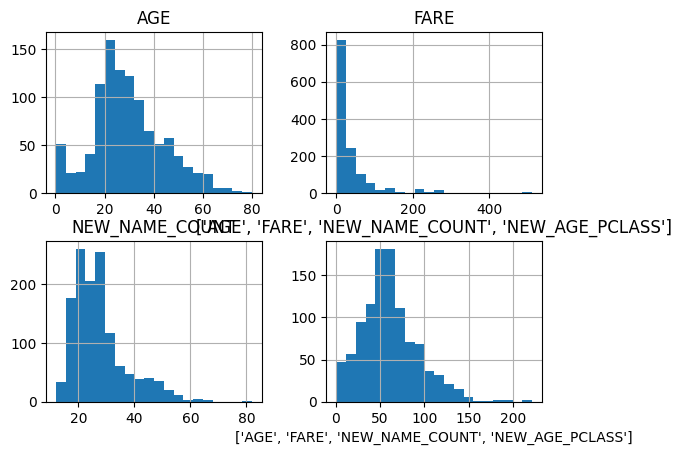

In [92]:
num_summary(df, num_cols, plot=True)


Analysis for SEX:
        SEX  Ratio
SEX               
male    843 64.400
female  466 35.600
##########################################


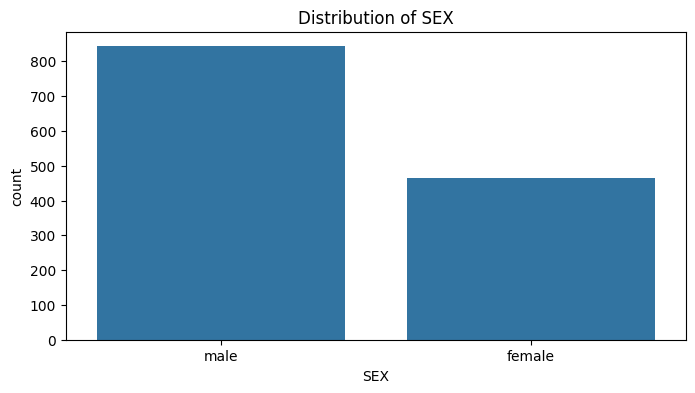


Analysis for EMBARKED:
          EMBARKED  Ratio
EMBARKED                 
S              914 69.824
C              270 20.626
Q              123  9.396
##########################################


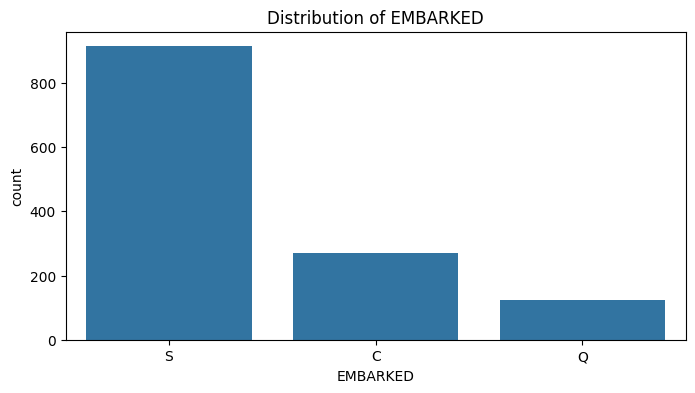


Analysis for NEW_TITLE:
           NEW_TITLE  Ratio
NEW_TITLE                  
Mr               757 57.830
Miss             260 19.862
Mrs              197 15.050
Master            61  4.660
Rev                8  0.611
Dr                 8  0.611
Col                4  0.306
Mlle               2  0.153
Major              2  0.153
Ms                 2  0.153
Lady               1  0.076
Sir                1  0.076
Mme                1  0.076
Don                1  0.076
Capt               1  0.076
Countess           1  0.076
Jonkheer           1  0.076
Dona               1  0.076
##########################################


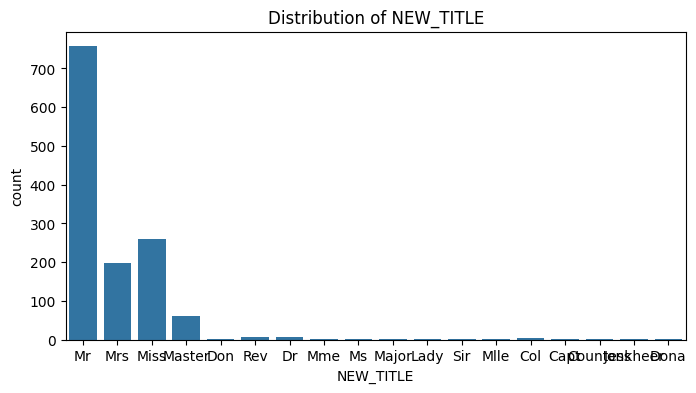


Analysis for NEW_IS_ALONE:
              NEW_IS_ALONE  Ratio
NEW_IS_ALONE                     
YES                    790 60.351
NO                     519 39.649
##########################################


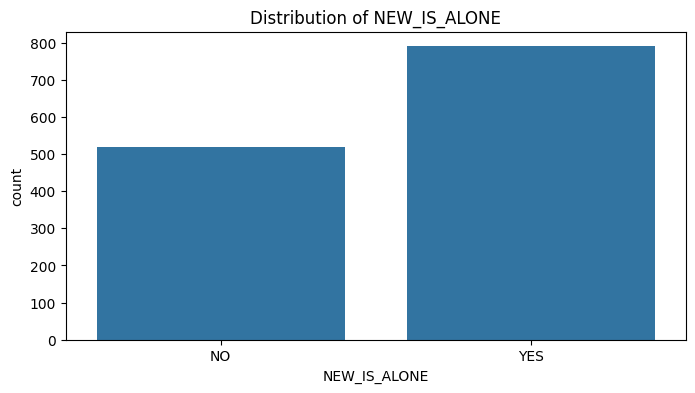


Analysis for NEW_AGE_CAT:
             NEW_AGE_CAT  Ratio
NEW_AGE_CAT                    
mature               834 63.713
young                154 11.765
senior                58  4.431
##########################################


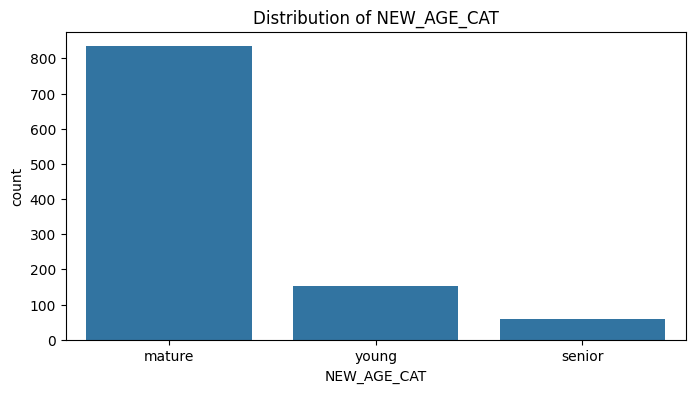


Analysis for NEW_SEX_CAT:
              NEW_SEX_CAT  Ratio
NEW_SEX_CAT                     
maturemale            780 59.587
maturefemale          434 33.155
seniormale             63  4.813
seniorfemale           32  2.445
##########################################


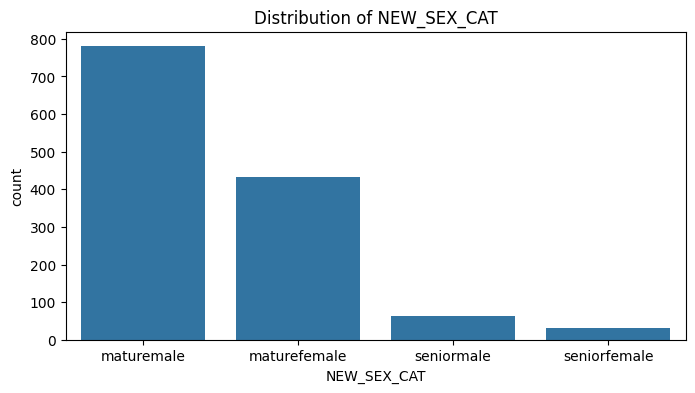


Analysis for SURVIVED:
          SURVIVED  Ratio
SURVIVED                 
0              815 62.261
1              494 37.739
##########################################


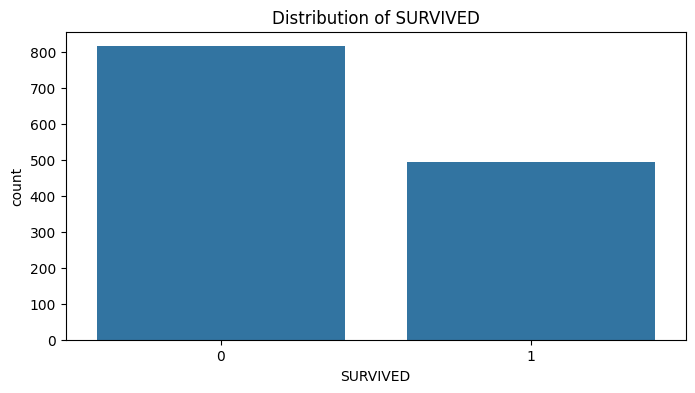


Analysis for PCLASS:
        PCLASS  Ratio
PCLASS               
3          709 54.163
1          323 24.675
2          277 21.161
##########################################


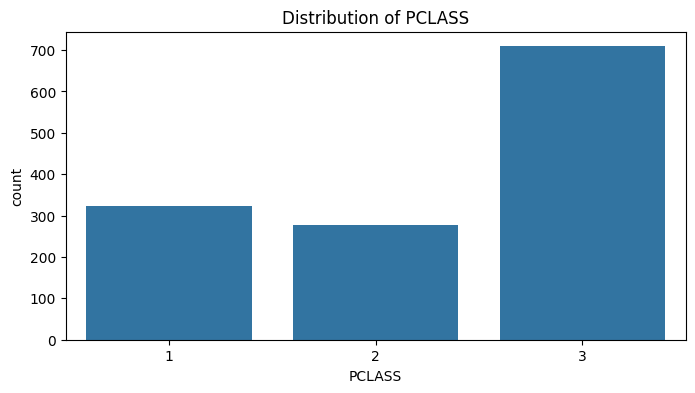


Analysis for SIBSP:
       SIBSP  Ratio
SIBSP              
0        891 68.067
1        319 24.370
2         42  3.209
4         22  1.681
3         20  1.528
8          9  0.688
5          6  0.458
##########################################


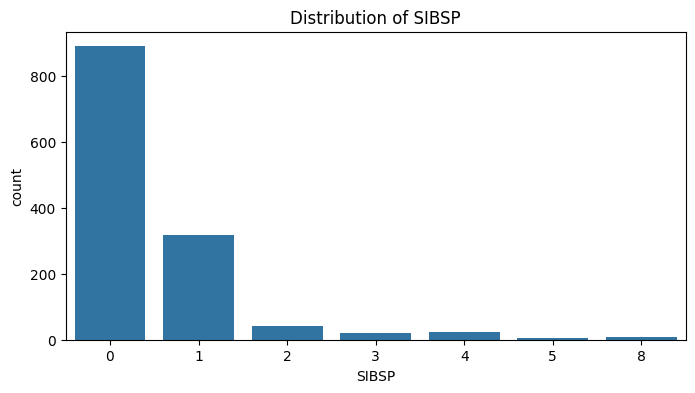


Analysis for PARCH:
       PARCH  Ratio
PARCH              
0       1002 76.547
1        170 12.987
2        113  8.633
3          8  0.611
5          6  0.458
4          6  0.458
6          2  0.153
9          2  0.153
##########################################


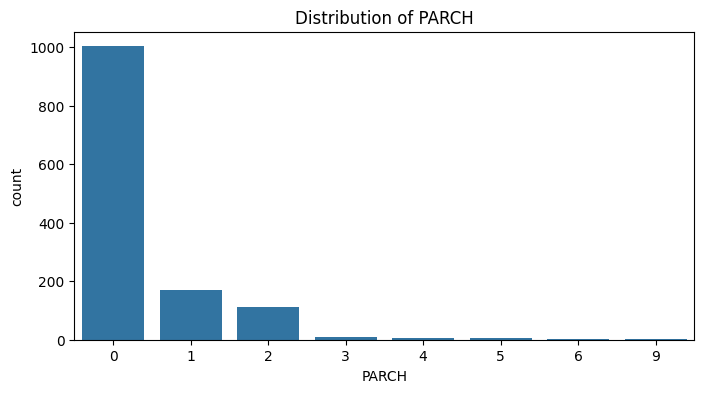


Analysis for NEW_CABIN_BOOL:
                NEW_CABIN_BOOL  Ratio
NEW_CABIN_BOOL                       
0                         1014 77.464
1                          295 22.536
##########################################


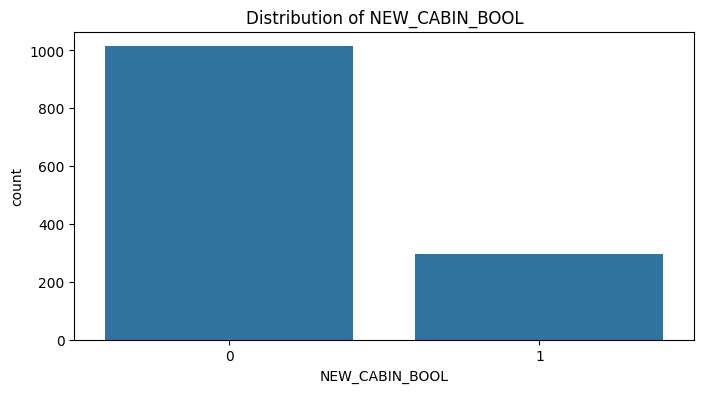


Analysis for NEW_NAME_WORD_COUNT:
                     NEW_NAME_WORD_COUNT  Ratio
NEW_NAME_WORD_COUNT                            
4                                    557 42.552
3                                    449 34.301
5                                    143 10.924
6                                     83  6.341
7                                     59  4.507
8                                     15  1.146
9                                      2  0.153
14                                     1  0.076
##########################################


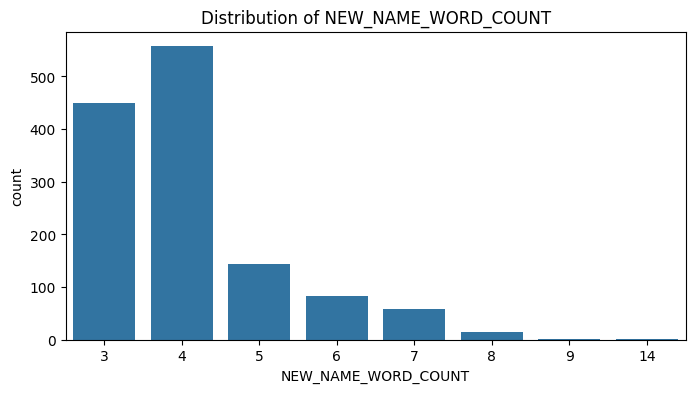


Analysis for NEW_NAME_DR:
             NEW_NAME_DR  Ratio
NEW_NAME_DR                    
0                   1293 98.778
1                     16  1.222
##########################################


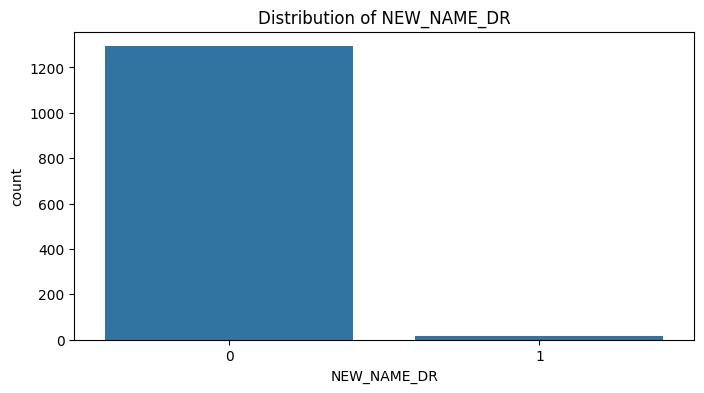


Analysis for NEW_FAMILY_SIZE:
                 NEW_FAMILY_SIZE  Ratio
NEW_FAMILY_SIZE                        
1                            790 60.351
2                            235 17.953
3                            159 12.147
4                             43  3.285
6                             25  1.910
5                             22  1.681
7                             16  1.222
11                            11  0.840
8                              8  0.611
##########################################


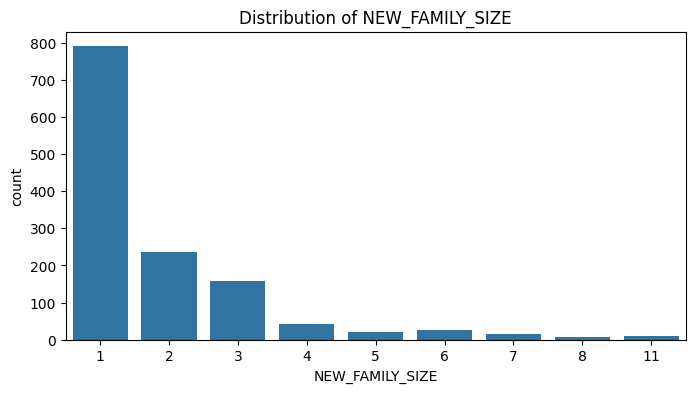

In [93]:
cat_summary(df, cat_cols, plot=True)

In [94]:
df.columns

Index(['PASSENGERID', 'SURVIVED', 'PCLASS', 'NAME', 'SEX', 'AGE', 'SIBSP', 'PARCH', 'TICKET', 'FARE', 'CABIN', 'EMBARKED', 'NEW_CABIN_BOOL', 'NEW_NAME_COUNT', 'NEW_NAME_WORD_COUNT', 'NEW_NAME_DR', 'NEW_TITLE', 'NEW_FAMILY_SIZE', 'NEW_AGE_PCLASS', 'NEW_IS_ALONE', 'NEW_AGE_CAT', 'NEW_SEX_CAT'], dtype='object')

## Outliers

In [95]:
num_cols = [col for col in num_cols if df[col].dtype.name != 'category']
for col in num_cols:
    print(col, check_outlier(df, col))

AGE True
FARE True
NEW_NAME_COUNT True
NEW_AGE_PCLASS True


In [96]:
for col in num_cols:
    replace_with_thresholds(df, col)

In [97]:
for col in num_cols:
    print(col, check_outlier(df, col))

AGE False
FARE False
NEW_NAME_COUNT False
NEW_AGE_PCLASS False


## Missing Values

In [98]:
def missing_values_table(dataframe, na_name=False):
    na_columns = [col for col in dataframe.columns if dataframe[col].isnull().sum() > 0]

    n_miss = dataframe[na_columns].isnull().sum().sort_values(ascending=False)
    ratio = (dataframe[na_columns].isnull().sum() / dataframe.shape[0] * 100).sort_values(ascending=False)
    missing_df = pd.concat([n_miss, np.round(ratio, 2)], axis=1, keys=['n_miss', 'ratio'])
    print(missing_df, end="\n")

    if na_name:
        return na_columns

In [99]:
missing_values_table(df)


                n_miss  ratio
CABIN             1014 77.460
AGE                263 20.090
NEW_AGE_PCLASS     263 20.090
NEW_AGE_CAT        263 20.090
EMBARKED             2  0.150
FARE                 1  0.080


In [100]:
## Cabin Bool adında yeni bir feature oluşturulduğu için Cabin sütunu gereksiz olduğundan silindi
df.drop(columns=["CABIN"], inplace=True)

In [101]:
missing_values_table(df)


                n_miss  ratio
AGE                263 20.090
NEW_AGE_PCLASS     263 20.090
NEW_AGE_CAT        263 20.090
EMBARKED             2  0.150
FARE                 1  0.080


In [102]:
df.drop(columns=["NAME", "TICKET"], inplace=True)

In [103]:
## Age NaN değerleri title bazında median ile dolduruldu ve age üzerinden
## değişkenleri yeniden üretmek zorundayız

In [104]:
df["AGE"] = df["AGE"].fillna(df.groupby("NEW_TITLE")["AGE"].transform("median"))

In [105]:
df["NEW_AGE_PCLASS"] = df["AGE"] * df["PCLASS"]

In [106]:
df.loc[(df["AGE"] < 18), "NEW_AGE_CAT"] = "young"
df.loc[(df["AGE"] >= 18) & (df["AGE"] < 56), "NEW_AGE_CAT"] = "mature"
df.loc[(df["AGE"] >= 56), "NEW_AGE_CAT"] = "senior"

In [107]:
df.loc[(df["SEX"] == "male") & (df["AGE"] <= 21), "NEW_SEX_CAT"] = "youngmale"
df.loc[(df["SEX"] == "male") & ((df["AGE"] > 21) & (df["AGE"] <= 50)), "NEW_SEX_CAT"] = "maturemale"
df.loc[(df["SEX"] == "male") & (df["AGE"] > 50), "NEW_SEX_CAT"] = "seniormale"
df.loc[(df["SEX"] == "female") & (df["AGE"] <= 21), "NEW_SEX_CAT"] = "youngfemale"
df.loc[(df["SEX"] == "female") & ((df["AGE"] > 21) & (df["AGE"] <= 50)), "NEW_SEX_CAT"] = "maturefemale"
df.loc[(df["SEX"] == "female") & (df["AGE"] > 50), "NEW_SEX_CAT"] = "seniorfemale"

In [108]:
missing_values_table(df)

          n_miss  ratio
EMBARKED       2  0.150
FARE           1  0.080


In [109]:
df = df.apply(lambda x: x.fillna(x.mode()[0]) if x.dtype == "O" and len(x.unique()) <= 10 else x, axis=0)

In [110]:
missing_values_table(df)

      n_miss  ratio
FARE       1  0.080


In [111]:
df[num_cols] = df[num_cols].apply(lambda x: x.fillna(x.mean()))

In [112]:
missing_values_table(df)

Empty DataFrame
Columns: [n_miss, ratio]
Index: []


## Label Encoding

In [113]:
binary_cols = [col for col in df.columns if df[col].dtype not in [int, float] and df[col].nunique() == 2]

In [114]:
binary_cols

['SURVIVED', 'SEX', 'NEW_NAME_DR', 'NEW_IS_ALONE']

In [115]:
def label_encoder(dataframe, binary_col):
    labelencoder = LabelEncoder()
    dataframe[binary_col] = labelencoder.fit_transform(dataframe[binary_col])
    return dataframe

In [116]:
for col in binary_cols:
    df = label_encoder(df, col)

In [117]:
df.head()

,PASSENGERID,SURVIVED,PCLASS,SEX,AGE,SIBSP,PARCH,FARE,EMBARKED,NEW_CABIN_BOOL,NEW_NAME_COUNT,NEW_NAME_WORD_COUNT,NEW_NAME_DR,NEW_TITLE,NEW_FAMILY_SIZE,NEW_AGE_PCLASS,NEW_IS_ALONE,NEW_AGE_CAT,NEW_SEX_CAT
0,1,0,3,1,22.000,1,0,7.250,S,0,23,4,0,Mr,2,66.000,0,mature,maturemale
1,2,1,1,0,38.000,1,0,66.344,C,1,45,7,0,Mrs,2,38.000,0,mature,maturefemale
2,3,1,3,0,26.000,0,0,7.925,S,0,22,3,0,Miss,1,78.000,1,mature,maturefemale
3,4,1,1,0,35.000,1,0,53.100,S,1,44,7,0,Mrs,2,35.000,0,mature,maturefemale
4,5,0,3,1,35.000,0,0,8.050,S,0,24,4,0,Mr,1,105.000,1,mature,maturemale


## Rare Encoding

In [118]:
def rare_analyser(dataframe, target, cat_cols):
    for col in cat_cols:
        print(col, ":", len(dataframe[col].value_counts()))
        print(pd.DataFrame({"COUNT": dataframe[col].value_counts(),
                            "RATIO": dataframe[col].value_counts() / len(dataframe),
                            "TARGET_MEAN": dataframe.groupby(col)[target].mean()}), end="\n\n\n")

In [119]:
rare_analyser(df, "SURVIVED", cat_cols)

SEX : 2
     COUNT  RATIO  TARGET_MEAN
SEX                           
0      466  0.356        0.826
1      843  0.644        0.129


EMBARKED : 3
          COUNT  RATIO  TARGET_MEAN
EMBARKED                           
C           270  0.206        0.493
Q           123  0.094        0.439
S           916  0.700        0.335


NEW_TITLE : 18
           COUNT  RATIO  TARGET_MEAN
NEW_TITLE                           
Capt           1  0.001        0.000
Col            4  0.003        0.250
Countess       1  0.001        1.000
Don            1  0.001        0.000
Dona           1  0.001        1.000
Dr             8  0.006        0.375
Jonkheer       1  0.001        0.000
Lady           1  0.001        1.000
Major          2  0.002        0.500
Master        61  0.047        0.377
Miss         260  0.199        0.788
Mlle           2  0.002        1.000
Mme            1  0.001        1.000
Mr           757  0.578        0.107
Mrs          197  0.150        0.868
Ms             2  0.002    

In [120]:
def rare_encoder(dataframe, rare_perc):
    temp_df = dataframe.copy()

    rare_columns = [col for col in temp_df.columns if temp_df[col].dtypes == 'O'
                    and (temp_df[col].value_counts() / len(temp_df) < rare_perc).any(axis=None)]

    for var in rare_columns:
        tmp = temp_df[var].value_counts() / len(temp_df)
        rare_labels = tmp[tmp < rare_perc].index
        temp_df[var] = np.where(temp_df[var].isin(rare_labels), 'Rare', temp_df[var])

    return temp_df

In [121]:
df = rare_encoder(df, 0.01)


## One-Hot Encoding

In [122]:
ohe_cols = [col for col in df.columns if 10 > df[col].nunique() > 2]

In [123]:
ohe_cols

['PCLASS',
 'SIBSP',
 'PARCH',
 'EMBARKED',
 'NEW_NAME_WORD_COUNT',
 'NEW_TITLE',
 'NEW_FAMILY_SIZE',
 'NEW_AGE_CAT',
 'NEW_SEX_CAT']

In [124]:
def one_hot_encoder(dataframe, categorical_cols, drop_first=True):
    dataframe = pd.get_dummies(dataframe, columns=categorical_cols, drop_first=drop_first)
    return dataframe

In [125]:
df = one_hot_encoder(df, ohe_cols)


In [126]:
df.head()

,PASSENGERID,SURVIVED,SEX,AGE,FARE,NEW_CABIN_BOOL,NEW_NAME_COUNT,NEW_NAME_DR,NEW_AGE_PCLASS,NEW_IS_ALONE,PCLASS_2,PCLASS_3,SIBSP_1,SIBSP_2,SIBSP_3,SIBSP_4,SIBSP_5,SIBSP_8,PARCH_1,PARCH_2,PARCH_3,PARCH_4,PARCH_5,PARCH_6,PARCH_9,EMBARKED_Q,EMBARKED_S,NEW_NAME_WORD_COUNT_4,NEW_NAME_WORD_COUNT_5,NEW_NAME_WORD_COUNT_6,NEW_NAME_WORD_COUNT_7,NEW_NAME_WORD_COUNT_8,NEW_NAME_WORD_COUNT_9,NEW_NAME_WORD_COUNT_14,NEW_TITLE_Miss,NEW_TITLE_Mr,NEW_TITLE_Mrs,NEW_TITLE_Rare,NEW_FAMILY_SIZE_2,NEW_FAMILY_SIZE_3,NEW_FAMILY_SIZE_4,NEW_FAMILY_SIZE_5,NEW_FAMILY_SIZE_6,NEW_FAMILY_SIZE_7,NEW_FAMILY_SIZE_8,NEW_FAMILY_SIZE_11,NEW_AGE_CAT_senior,NEW_AGE_CAT_young,NEW_SEX_CAT_maturemale,NEW_SEX_CAT_seniorfemale,NEW_SEX_CAT_seniormale,NEW_SEX_CAT_youngfemale,NEW_SEX_CAT_youngmale
0,1,0,1,22.000,7.250,0,23,0,66.000,0,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,2,1,0,38.000,66.344,1,45,0,38.000,0,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,3,1,0,26.000,7.925,0,22,0,78.000,1,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,4,1,0,35.000,53.100,1,44,0,35.000,0,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,5,0,1,35.000,8.050,0,24,0,105.000,1,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False


In [127]:
cat_cols, num_cols, cat_but_car = grab_col_names(df)


Observations: 1309
Variables: 53
cat_cols: 48
num_cols: 5
cat_but_car: 0
num_but_cat: 48


In [128]:
num_cols

['PASSENGERID', 'AGE', 'FARE', 'NEW_NAME_COUNT', 'NEW_AGE_PCLASS']

In [129]:
num_cols = [col for col in num_cols if col not in ["PASSENGERID"]]
num_cols


['AGE', 'FARE', 'NEW_NAME_COUNT', 'NEW_AGE_PCLASS']

In [130]:
rare_analyser(df, "SURVIVED", cat_cols)

SURVIVED : 2
          COUNT  RATIO  TARGET_MEAN
SURVIVED                           
0           815  0.623        0.000
1           494  0.377        1.000


SEX : 2
     COUNT  RATIO  TARGET_MEAN
SEX                           
0      466  0.356        0.826
1      843  0.644        0.129


NEW_CABIN_BOOL : 2
                COUNT  RATIO  TARGET_MEAN
NEW_CABIN_BOOL                           
0                1014  0.775        0.310
1                 295  0.225        0.610


NEW_NAME_DR : 2
             COUNT  RATIO  TARGET_MEAN
NEW_NAME_DR                           
0             1293  0.988        0.377
1               16  0.012        0.438


NEW_IS_ALONE : 2
              COUNT  RATIO  TARGET_MEAN
NEW_IS_ALONE                           
0               519  0.396        0.507
1               790  0.604        0.292


PCLASS_2 : 2
          COUNT  RATIO  TARGET_MEAN
PCLASS_2                           
False      1032  0.788        0.365
True        277  0.212        0.422


PCLASS

## Feature Selection

In [131]:
useless_cols = [col for col in df.columns if df[col].nunique() == 2 and (df[col].value_counts() / len(df) < 0.01).any(axis=None)]

In [132]:
useless_cols

['SIBSP_5',
 'SIBSP_8',
 'PARCH_3',
 'PARCH_4',
 'PARCH_5',
 'PARCH_6',
 'PARCH_9',
 'NEW_NAME_WORD_COUNT_9',
 'NEW_NAME_WORD_COUNT_14',
 'NEW_FAMILY_SIZE_8',
 'NEW_FAMILY_SIZE_11']

In [133]:
df.drop(columns=useless_cols, inplace=True)

# Standart Scaler

In [134]:
scaler = StandardScaler()


In [135]:
df[num_cols] = scaler.fit_transform(df[num_cols])

In [136]:
df[num_cols].head()

,AGE,FARE,NEW_NAME_COUNT,NEW_AGE_PCLASS
0,-0.567,-0.820,-0.443,0.091
1,0.661,2.024,2.185,-0.802
2,-0.260,-0.787,-0.562,0.473
3,0.431,1.387,2.066,-0.898
4,0.431,-0.781,-0.323,1.334


## Model

In [137]:
y = df["SURVIVED"]
X = df.drop(columns=["PASSENGERID", "SURVIVED"], axis=1)

In [138]:
missing_values_table(X)

Empty DataFrame
Columns: [n_miss, ratio]
Index: []


In [139]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=17)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=17)

In [140]:
from sklearn.ensemble import RandomForestClassifier

In [141]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

rf_model = RandomForestClassifier(random_state=46)
rf_model.fit(X_train, y_train)

# Validation seti üzerinde değerlendirme
y_pred_val = rf_model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_pred_val)
print("Validation Accuracy:", val_accuracy)

# Final test seti üzerinde değerlendirme
y_pred_test = rf_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred_test)
print("Test Accuracy:", test_accuracy)

Validation Accuracy: 0.8426395939086294
Test Accuracy: 0.8112244897959183


## Cross Validation

https://www.linkedin.com/feed/update/urn:li:activity:7253874648189181952?utm_source=share&utm_medium=member_desktop

In [142]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [143]:
# Daha detaylı cross validation
def cv_model_evaluation(model, X, y, fold_count=5):
    skf = StratifiedKFold(n_splits=fold_count, shuffle=True, random_state=42)
    
    # Metrik listelerini oluştur
    cv_accuracy = []
    cv_precision = []
    cv_recall = []
    cv_f1 = []
    
    # Her fold için modeli eğit ve değerlendir
    for fold, (train_index, val_index) in enumerate(skf.split(X, y), 1):
        X_train, X_val = X.iloc[train_index], X.iloc[val_index]
        y_train, y_val = y.iloc[train_index], y.iloc[val_index]
        
        # Modeli eğit
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        
        # Metrikleri hesapla
        fold_accuracy = accuracy_score(y_val, y_pred)
        fold_precision = precision_score(y_val, y_pred)
        fold_recall = recall_score(y_val, y_pred)
        fold_f1 = f1_score(y_val, y_pred)
        
        # Metrikleri listelere ekle
        cv_accuracy.append(fold_accuracy)
        cv_precision.append(fold_precision)
        cv_recall.append(fold_recall)
        cv_f1.append(fold_f1)
        
        print(f"Fold {fold}:")
        print(f"Accuracy: {fold_accuracy:.3f}")
        print(f"Precision: {fold_precision:.3f}")
        print(f"Recall: {fold_recall:.3f}")
        print(f"F1-Score: {fold_f1:.3f}")
        print("-" * 50)
    
    # Ortalama metrikleri yazdır
    print("\nOrtalama Metrikler:")
    print(f"Accuracy: {np.mean(cv_accuracy):.3f} (+/- {np.std(cv_accuracy) * 2:.3f})")
    print(f"Precision: {np.mean(cv_precision):.3f} (+/- {np.std(cv_precision) * 2:.3f})")
    print(f"Recall: {np.mean(cv_recall):.3f} (+/- {np.std(cv_recall) * 2:.3f})")
    print(f"F1-Score: {np.mean(cv_f1):.3f} (+/- {np.std(cv_f1) * 2:.3f})")

In [144]:
# Modeli değerlendir
rf_model = RandomForestClassifier(random_state=46)
cv_model_evaluation(rf_model, X, y)

Fold 1:
Accuracy: 0.836
Precision: 0.750
Recall: 0.848
F1-Score: 0.796
--------------------------------------------------


Fold 2:
Accuracy: 0.844
Precision: 0.830
Recall: 0.737
F1-Score: 0.781
--------------------------------------------------
Fold 3:
Accuracy: 0.878
Precision: 0.845
Recall: 0.828
F1-Score: 0.837
--------------------------------------------------
Fold 4:
Accuracy: 0.832
Precision: 0.802
Recall: 0.737
F1-Score: 0.768
--------------------------------------------------
Fold 5:
Accuracy: 0.824
Precision: 0.789
Recall: 0.724
F1-Score: 0.755
--------------------------------------------------

Ortalama Metrikler:
Accuracy: 0.843 (+/- 0.037)
Precision: 0.803 (+/- 0.066)
Recall: 0.775 (+/- 0.104)
F1-Score: 0.787 (+/- 0.056)


In [145]:
# Yeni ürettiğimiz değişkenler?

In [146]:
def plot_importance(model, features, num=len(X)):
    feature_imp = pd.DataFrame({'Value': model.feature_importances_, 'Feature': features.columns})
    plt.figure(figsize=(10, 10))
    sns.set(font_scale=1)
    sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False), palette="viridis")

    plt.title("Features")
    plt.tight_layout()
    plt.show()


C:\Users\ASUS\AppData\Local\Temp\ipykernel_27304\2654746156.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False), palette="viridis")


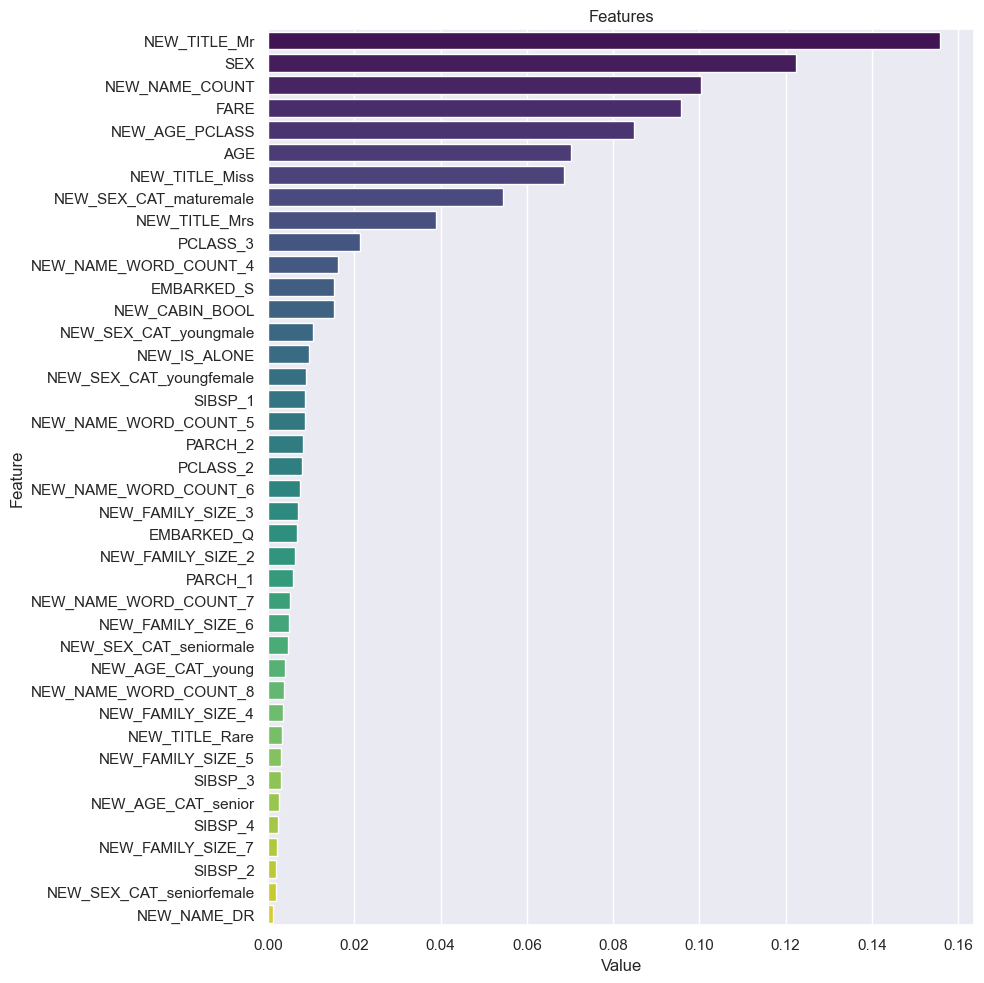

In [147]:
plot_importance(rf_model, X_train)

## PCA

In [148]:
scaler = StandardScaler()

In [149]:
missing_values_table(df)

Empty DataFrame
Columns: [n_miss, ratio]
Index: []


In [150]:
df.dropna(inplace=True)
missing_values_table(df)


Empty DataFrame
Columns: [n_miss, ratio]
Index: []


In [151]:
X = df.drop(columns=["PASSENGERID", "SURVIVED"], axis=1)
y = df["SURVIVED"]

In [152]:
X_scaled = scaler.fit_transform(X)


In [153]:
from sklearn.decomposition import PCA

In [154]:
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

In [155]:
print("Orijinal özellik sayısı: ", X.shape[1])
print("PCA sonrası özellik sayısı: ", X_pca.shape[1])

Orijinal özellik sayısı:  40
PCA sonrası özellik sayısı:  26


In [156]:
Y = df["SURVIVED"]

In [157]:
X_train_pca, X_temp_pca, y_train, y_temp = train_test_split(X_pca, Y, test_size=0.3, random_state=2)
X_test_pca, X_val_pca, y_test, y_val = train_test_split(X_temp_pca, y_temp, test_size=0.5, random_state=2)

In [158]:
# PCA ile model eğitimi
rf_model_pca = RandomForestClassifier(random_state=46)
rf_model_pca.fit(X_train_pca, y_train)

# Validation seti üzerinde değerlendirme
y_pred_val_pca = rf_model_pca.predict(X_val_pca)

# Test seti üzerinde değerlendirme
y_pred_test_pca = rf_model_pca.predict(X_test_pca)

# Performans metriklerinin hesaplanması
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Validation metrikleri
val_accuracy = accuracy_score(y_val, y_pred_val_pca)
val_precision = precision_score(y_val, y_pred_val_pca)
val_recall = recall_score(y_val, y_pred_val_pca)
val_f1 = f1_score(y_val, y_pred_val_pca)
val_conf_matrix = confusion_matrix(y_val, y_pred_val_pca)

# Test metrikleri
test_accuracy = accuracy_score(y_test, y_pred_test_pca)
test_precision = precision_score(y_test, y_pred_test_pca)
test_recall = recall_score(y_test, y_pred_test_pca)
test_f1 = f1_score(y_test, y_pred_test_pca)
test_conf_matrix = confusion_matrix(y_test, y_pred_test_pca)

print("PCA Uygulanmış Model Performans Metrikleri:")
print("\nValidation Set Metrikleri:")
print(f"Accuracy: {val_accuracy:.3f}")
print(f"Precision: {val_precision:.3f}")
print(f"Recall: {val_recall:.3f}")
print(f"F1-score: {val_f1:.3f}")
print("\nValidation Confusion Matrix:")
print(val_conf_matrix)

print("\nTest Set Metrikleri:")
print(f"Accuracy: {test_accuracy:.3f}")
print(f"Precision: {test_precision:.3f}")
print(f"Recall: {test_recall:.3f}")
print(f"F1-score: {test_f1:.3f}")
print("\nTest Confusion Matrix:")
print(test_conf_matrix)

PCA Uygulanmış Model Performans Metrikleri:

Validation Set Metrikleri:
Accuracy: 0.853
Precision: 0.823
Recall: 0.739
F1-score: 0.779

Validation Confusion Matrix:
[[117  11]
 [ 18  51]]

Test Set Metrikleri:
Accuracy: 0.832
Precision: 0.815
Recall: 0.716
F1-score: 0.763

Test Confusion Matrix:
[[110  12]
 [ 21  53]]


In [159]:
def cv_model_evaluation(model, X_train, X_val, X_test, y_train, y_val, y_test, fold_count=5):
    # X_train'i DataFrame'e, y_train'i Series'e çevir ve indexleri resetle
    if isinstance(X_train, np.ndarray):
        X_train = pd.DataFrame(X_train).reset_index(drop=True)
    if isinstance(y_train, np.ndarray):
        y_train = pd.Series(y_train).reset_index(drop=True)
    else:
        y_train = y_train.reset_index(drop=True)
        X_train = X_train.reset_index(drop=True)
    
    skf = StratifiedKFold(n_splits=fold_count, shuffle=True, random_state=42)
    
    cv_accuracy = []
    cv_precision = []
    cv_recall = []
    cv_f1 = []
    
    # Cross-validation değerlendirmesi (sadece train seti üzerinde)
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
        X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        
        model.fit(X_fold_train, y_fold_train)
        y_fold_pred = model.predict(X_fold_val)
        
        fold_accuracy = accuracy_score(y_fold_val, y_fold_pred)
        fold_precision = precision_score(y_fold_val, y_fold_pred)
        fold_recall = recall_score(y_fold_val, y_fold_pred)
        fold_f1 = f1_score(y_fold_val, y_fold_pred)
        
        cv_accuracy.append(fold_accuracy)
        cv_precision.append(fold_precision)
        cv_recall.append(fold_recall)
        cv_f1.append(fold_f1)
        
        print(f"Fold {fold}:")
        print(f"Accuracy: {fold_accuracy:.3f}")
        print(f"Precision: {fold_precision:.3f}")
        print(f"Recall: {fold_recall:.3f}")
        print(f"F1-Score: {fold_f1:.3f}")
        print("-" * 50)
    
    print("\nCross-Validation Ortalama Metrikler:")
    print(f"Accuracy: {np.mean(cv_accuracy):.3f} (+/- {np.std(cv_accuracy) * 2:.3f})")
    print(f"Precision: {np.mean(cv_precision):.3f} (+/- {np.std(cv_precision) * 2:.3f})")
    print(f"Recall: {np.mean(cv_recall):.3f} (+/- {np.std(cv_recall) * 2:.3f})")
    print(f"F1-Score: {np.mean(cv_f1):.3f} (+/- {np.std(cv_f1) * 2:.3f})")
    
    # Tüm train seti üzerinde model eğitimi
    model.fit(X_train, y_train)
    
    # Validation seti değerlendirmesi
    y_val_pred = model.predict(X_val)
    print("\nValidation Set Metrikleri:")
    print(f"Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
    print(f"Precision: {precision_score(y_val, y_val_pred):.3f}")
    print(f"Recall: {recall_score(y_val, y_val_pred):.3f}")
    print(f"F1-Score: {f1_score(y_val, y_val_pred):.3f}")
    print("\nValidation Confusion Matrix:")
    print(confusion_matrix(y_val, y_val_pred))
    
    # Test seti değerlendirmesi
    y_test_pred = model.predict(X_test)
    print("\nTest Set Metrikleri:")
    print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.3f}")
    print(f"Precision: {precision_score(y_test, y_test_pred):.3f}")
    print(f"Recall: {recall_score(y_test, y_test_pred):.3f}")
    print(f"F1-Score: {f1_score(y_test, y_test_pred):.3f}")
    print("\nTest Confusion Matrix:")
    print(confusion_matrix(y_test, y_test_pred))

In [160]:
# PCA sonrası verileri hazırla
X_pca_df = pd.DataFrame(X_pca)
y_series = pd.Series(y)

# Modeli değerlendir
rf_model_pca = RandomForestClassifier(random_state=46)
cv_model_evaluation(rf_model_pca, 
                   X_train_pca,  # PCA uygulanmış train seti
                   X_val_pca,    # PCA uygulanmış validation seti
                   X_test_pca,   # PCA uygulanmış test seti
                   y_train,      # Train set etiketleri
                   y_val,        # Validation set etiketleri
                   y_test)       # Test set etiketleri

Fold 1:
Accuracy: 0.832
Precision: 0.823
Recall: 0.718
F1-Score: 0.767
--------------------------------------------------
Fold 2:
Accuracy: 0.842
Precision: 0.806
Recall: 0.771
F1-Score: 0.788
--------------------------------------------------
Fold 3:
Accuracy: 0.858
Precision: 0.833
Recall: 0.786
F1-Score: 0.809
--------------------------------------------------
Fold 4:
Accuracy: 0.803
Precision: 0.758
Recall: 0.714
F1-Score: 0.735
--------------------------------------------------
Fold 5:
Accuracy: 0.825
Precision: 0.764
Recall: 0.786
F1-Score: 0.775
--------------------------------------------------

Cross-Validation Ortalama Metrikler:
Accuracy: 0.832 (+/- 0.036)
Precision: 0.797 (+/- 0.061)
Recall: 0.755 (+/- 0.064)
F1-Score: 0.775 (+/- 0.049)

Validation Set Metrikleri:
Accuracy: 0.853
Precision: 0.823
Recall: 0.739
F1-Score: 0.779

Validation Confusion Matrix:
[[117  11]
 [ 18  51]]

Test Set Metrikleri:
Accuracy: 0.832
Precision: 0.815
Recall: 0.716
F1-Score: 0.763

Test Confus

In [161]:
## Hiç bir işlem yapılmadan elde edilecek skor?

In [162]:
dff = pd.read_csv('datasets/titanic/train.csv')

In [163]:
dff.dropna(inplace=True)


In [164]:
dff = pd.get_dummies(dff, columns=["Sex", "Embarked"], drop_first=True)

In [165]:
y = dff["Survived"]


In [166]:
X = dff.drop(columns=["PassengerId", "Survived", "Name", "Ticket", "Cabin"], axis=1)

In [167]:
# Önce veriyi train ve geçici set olarak ikiye bölüyoruz
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=17)

# Sonra geçici seti validation ve test olarak ikiye bölüyoruz
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=17)

In [168]:
# Model eğitimi
rf_model = RandomForestClassifier(random_state=46)
rf_model.fit(X_train, y_train)

# Validation seti üzerinde değerlendirme
y_pred_val = rf_model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_pred_val)
print("Validation Accuracy:", val_accuracy)

# Final test seti üzerinde değerlendirme
y_pred_test = rf_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred_test)
print("Test Accuracy:", test_accuracy)

# Daha detaylı metrikler için
print("\nValidation Set Metrikleri:")
print(f"Precision: {precision_score(y_val, y_pred_val):.3f}")
print(f"Recall: {recall_score(y_val, y_pred_val):.3f}")
print(f"F1-score: {f1_score(y_val, y_pred_val):.3f}")

print("\nTest Set Metrikleri:")
print(f"Precision: {precision_score(y_test, y_pred_test):.3f}")
print(f"Recall: {recall_score(y_test, y_pred_test):.3f}")
print(f"F1-score: {f1_score(y_test, y_pred_test):.3f}")

Validation Accuracy: 0.7142857142857143
Test Accuracy: 0.7037037037037037

Validation Set Metrikleri:
Precision: 0.882
Recall: 0.714
F1-score: 0.789

Test Set Metrikleri:
Precision: 0.824
Recall: 0.737
F1-score: 0.778
